# 16 — UR5e kinematics and Jacobians

**Objectives.** Compose six DH transforms, extract tool position/orientation, compute the geometric Jacobian, and visualize the arm. The model uses published geometry but conservative tutorial limits. It does **not** represent torque-level rigid-body dynamics or a safety-rated controller.


In [1]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Build reusable UR5e forward-kinematics and Jacobian functions

A six-element SX joint vector is passed through the editable UR5e model.
Two `ca.Function` objects store the base-to-tool transform and geometric
Jacobian graphs for repeated evaluation. The numerical results at the zero
configuration are converted to NumPy for rank checks and visualization.

With one Denavit–Hartenberg transform per joint, forward kinematics is


$$
\begin{equation}
T_6^0(q)=\prod_{i=1}^{6}{}^{i-1}T_i(q_i)
=\begin{bmatrix}R(q)&p(q)\\0&1\end{bmatrix}.
\end{equation}
$$


The geometric Jacobian maps joint velocity to tool twist:

$$
\begin{equation}
\begin{bmatrix}v_{\mathrm{tool}}\\
\omega_{\mathrm{tool}}\end{bmatrix}
=J_g(q)\dot q.
\end{equation}
$$

`plot_ur5e` evaluates intermediate frame origins to display a transparent
stick representation of the same kinematic chain.


base-to-tool transform at q=0: [[ 1.000000e+00  0.000000e+00  0.000000e+00 -8.172000e-01]
 [ 0.000000e+00  6.123234e-17 -1.000000e+00 -2.329000e-01]
 [ 0.000000e+00  1.000000e+00  6.123234e-17  6.280000e-02]
 [ 0.000000e+00  0.000000e+00  0.000000e+00  1.000000e+00]]
Jacobian rank: 5


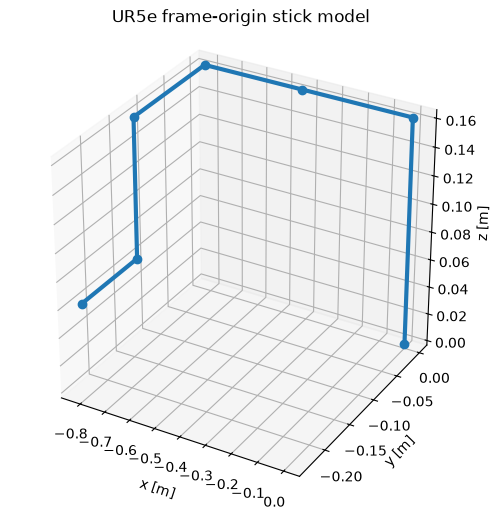

In [2]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.models.ur5e import (
    UR5eParameters,
    forward_kinematics,
    geometric_jacobian,
)
from casadi_tutorial.plotting import plot_ur5e

parameters = UR5eParameters()
joint_vector = ca.SX.sym("joint_vector", 6)

# Function stores each symbolic kinematic graph for fast repeated evaluation.
forward_map = ca.Function(
    "forward_kinematics",
    [joint_vector],
    [forward_kinematics(joint_vector, parameters)],
    ["joint_angles"],
    ["base_to_tool"],
)
jacobian_map = ca.Function(
    "tool_jacobian",
    [joint_vector],
    [geometric_jacobian(joint_vector, parameters)],
    ["joint_angles"],
    ["geometric_jacobian"],
)

zero_configuration = np.zeros(6)
tool_transform = np.asarray(forward_map(zero_configuration).full())
tool_jacobian = np.asarray(jacobian_map(zero_configuration).full())
print("base-to-tool transform at q=0:", tool_transform)
print("Jacobian rank:", np.linalg.matrix_rank(tool_jacobian))
assert tool_transform.shape == (4, 4)
assert tool_jacobian.shape == (6, 6)

plot_ur5e(zero_configuration)
plt.title("UR5e frame-origin stick model")
plt.show()

### Verify the translational Jacobian by a directional perturbation

The cell checks the top three rows of the geometric Jacobian, which map
joint rates to tool linear velocity. It evaluates forward kinematics at
two nearby configurations and compares the centered finite difference with
the exact Jacobian-vector product.

For tool position $p(q)$ and joint-space direction $v$,

$$
\begin{equation}
\frac{\partial p}{\partial q}v
\approx
\frac{p(q+\varepsilon v)-p(q-\varepsilon v)}{2\varepsilon},
\qquad \varepsilon=10^{-6}.
\end{equation}
$$

The exact left-hand side is `tool_jacobian[:3] @ direction`. Agreement
checks frame propagation, joint-axis orientation, and Jacobian assembly in
the editable robot model.


In [3]:
# Check the translational Jacobian-vector product with a centered difference.
direction = np.array([0.2, -0.1, 0.3, 0.1, -0.2, 0.05])
finite_difference_step = 1e-6
forward_position = np.asarray(
    forward_map(zero_configuration + finite_difference_step * direction).full()
)[:3, 3]
backward_position = np.asarray(
    forward_map(zero_configuration - finite_difference_step * direction).full()
)[:3, 3]
finite_difference = (forward_position - backward_position) / (2 * finite_difference_step)

np.testing.assert_allclose(
    finite_difference,
    tool_jacobian[:3] @ direction,
    rtol=1e-6,
    atol=1e-8,
)

The top Jacobian block maps joint velocity to tool linear velocity; the bottom maps to angular velocity. Loss of rank indicates a kinematic singularity. Orientation errors should use a geometrically meaningful representation rather than subtracting rotation-matrix entries blindly.

**Common mistakes:** mixing standard/modified DH tables, millimetres/metres, degrees/radians, and frame conventions. **Recap:** validate a symbolic Jacobian with directional finite differences and known poses before optimizing.
